# 記述統計：2025年度最低賃金の発効時期とパート新規求人数

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WUZICANGJIE/minimal_wage_job/blob/main/2026-10-28/descriptive_stats.ipynb)


第1回発表（2026年10月21日）で示した2つのデータについて、記述統計を確認する。発表で次回までの作業とした、**改定前の求人の動き**と**引上げ幅**を中心に見る。

| データ | ファイル | 使用する部分 |
|---|---|---|
| 厚生労働省（2026a）一般職業紹介状況 第12表 | `data/raw/estat_shokugyo_t12_shinki_kyujin.xlsx` | 第12表-3「一般パートタイム」の新規求人数（受理地）、月次、47都道府県 |
| 厚生労働省（2026b）地域別最低賃金改定状況 | `data/raw/mhlw_saitei_chingin_kaitei.xlsx` | 令和6年度・令和7年度（2025年度）の改定額と発効年月日 |

データの期間は発表と同じく **2023年1月〜2026年8月** とする。前年同月比には前年のデータが必要なため、全期間の系列で計算してから期間を絞る。

**実行方法：** 上のボタンからGoogle Colabで開き、「ランタイム → すべてのセルを実行」を選ぶ。データと日本語フォントは最初のセルで自動的に取得する。

**注意：** 求人数はハローワークが受理した求人の数であり、実際の採用人数ではなく、他の求人媒体も含まない。

In [1]:
from pathlib import Path
import unicodedata
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

REPO_RAW = "https://raw.githubusercontent.com/WUZICANGJIE/minimal_wage_job/main"
RAW_FILES = ["estat_shokugyo_t12_shinki_kyujin.xlsx", "mhlw_saitei_chingin_kaitei.xlsx"]

# リポジトリ内で開いた場合は data/raw を使い、Colab などで見つからなければ GitHub から取得する
local = [p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir()]
ROOT = local[0] if local else Path.cwd()
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
if not local:
    RAW.mkdir(parents=True, exist_ok=True)
    for f in RAW_FILES:
        urllib.request.urlretrieve(f"{REPO_RAW}/data/raw/{f}", RAW / f)
T12, MW = (RAW / f for f in RAW_FILES)


# グラフの日本語フォント：どの環境でも同じ表示になるよう Noto Sans JP を取得して使う
font_path = ROOT / ".cache" / "NotoSansJP-Regular.otf"
if not font_path.exists():
    font_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://github.com/notofonts/noto-cjk/raw/main/Sans/SubsetOTF/JP/NotoSansJP-Regular.otf", font_path)
font_manager.fontManager.addfont(font_path)
jp_font = font_manager.FontProperties(fname=font_path).get_name()

START, END = pd.Period("2023-01", "M"), pd.Period("2026-08", "M")

pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# グラフの配色：発効時期の3グループ（青・橙・緑）
GROUP_ORDER = ["10月発効", "11月発効", "12月以降発効"]
COLORS = {"10月発効": "#2a78d6", "11月発効": "#eb6834", "12月以降発効": "#1baf7a"}
plt.rcParams.update({
    "font.family": jp_font,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10,
})

## 1. データの読み込み

### 1.1 パート新規求人数（第12表-3）

Excelの構成：2行目が都道府県名で、4行目以降に年平均・年度平均・月次の値が並ぶ。「月」列に値がある月次の行だけを使う。

In [2]:
def load_t12(sheet):
    raw = pd.read_excel(T12, sheet_name=sheet, header=None)
    names = raw.iloc[1, 3:].tolist()  # 全国 + 47都道府県
    body = raw[raw[2].notna() & raw[0].astype(str).str.match(r"\d{4}年")].copy()
    year = body[0].astype(str).str.extract(r"(\d{4})")[0].astype(int)
    month = body[2].map(lambda s: unicodedata.normalize("NFKC", s)).str.extract(r"(\d+)")[0].astype(int)
    wide = body.iloc[:, 3:3 + len(names)].astype(float)
    wide.columns = names
    wide.index = pd.PeriodIndex.from_fields(year=year, month=month, freq="M")
    wide.index.name = "month"
    return wide

sheets = pd.ExcelFile(T12).sheet_names
print(sheets)
part_wide = load_t12(sheets[2])  # 第１２表－３（一般パート）
national = part_wide.pop("全国")
PREFS = part_wide.columns.tolist()
print(f"{len(PREFS)}都道府県、{part_wide.index.min()}〜{part_wide.index.max()}、欠損値 {int(part_wide.isna().sum().sum())}")
part_wide.loc[START:END].iloc[:3, :6]

['第１２表－１（パート含む一般）', '第１２表ー２（パート除く一般）', '第１２表－３（一般パート）', '第１２表ー４（パート含む常用）', '第１２表ー５（パート除く常用）', '第１２表ー６（常用的パート）']
47都道府県、2013-01〜2026-08、欠損値 0


,北海道,青森県,岩手県,宮城県,秋田県,山形県
month,,,,,,
2023-01,"12,939.00","3,739.00","4,937.00","6,482.00","3,566.00","3,288.00"
2023-02,"13,437.00","3,676.00","5,460.00","7,504.00","3,587.00","3,954.00"
2023-03,"13,100.00","4,143.00","3,651.00","6,004.00","3,458.00","3,453.00"


### 1.2 地域別最低賃金（2024年度・2025年度）

都道府県名には全角スペースが含まれる（例：「青　森」）ため、第12表の表記（「青森県」）にそろえる。

In [3]:
mw_raw = pd.read_excel(MW, header=None)

def mw_year(label):
    j = mw_raw.columns[mw_raw.iloc[0] == label][0]
    block = mw_raw.iloc[2:49, [0, j, j + 1]]
    block.columns = ["pref", "mw", "date"]
    return block

def to_t12_name(s):
    s = "".join(str(s).split())
    return next(n for n in (s, s + "県", s + "府", s + "都") if n in PREFS)

r6, r7 = mw_year("令和６年度"), mw_year("令和７年度")
mw = pd.DataFrame({
    "pref": r7["pref"].map(to_t12_name).values,
    "mw_2024": r6["mw"].astype(int).values,
    "mw_2025": r7["mw"].astype(int).values,
    "effective": pd.to_datetime(r7["date"]).values,
})
assert mw["pref"].tolist() == PREFS, "都道府県の順序または名称が一致しない"

mw["raise_yen"] = mw["mw_2025"] - mw["mw_2024"]
mw["raise_pct"] = 100 * mw["raise_yen"] / mw["mw_2024"]
mw["eff_month"] = mw["effective"].dt.to_period("M")
# 新しい最低賃金が丸1か月適用される最初の月（1日発効ならその月）
mw["first_full_month"] = mw["eff_month"].where(mw["effective"].dt.day == 1, mw["eff_month"] + 1)
mw["group"] = pd.Categorical(
    mw["eff_month"].map(lambda p: "10月発効" if p == pd.Period("2025-10", "M")
                        else "11月発効" if p == pd.Period("2025-11", "M") else "12月以降発効"),
    categories=GROUP_ORDER, ordered=True)
mw = mw.set_index("pref")
mw.sort_values("effective").head()

,mw_2024,mw_2025,effective,raise_yen,raise_pct,eff_month,first_full_month,group
pref,,,,,,,,
栃木県,1004,1068,2025-10-01,64,6.37,2025-10,2025-10,10月発効
新潟県,985,1050,2025-10-02,65,6.60,2025-10,2025-11,10月発効
長野県,998,1061,2025-10-03,63,6.31,2025-10,2025-11,10月発効
東京都,1163,1226,2025-10-03,63,5.42,2025-10,2025-11,10月発効
千葉県,1076,1140,2025-10-03,64,5.95,2025-10,2025-11,10月発効


## 2. 2025年度最低賃金改定の記述統計

In [4]:
mw[["mw_2024", "mw_2025", "raise_yen", "raise_pct"]].describe().T

,count,mean,std,min,25%,50%,75%,max
mw_2024,47.00,998.36,53.26,951.00,955.50,984.00,"1,013.50","1,163.00"
mw_2025,47.00,"1,067.09",49.61,"1,023.00","1,033.00","1,051.00","1,077.50","1,226.00"
raise_yen,47.00,68.72,6.05,63.00,64.00,65.00,73.00,82.00
raise_pct,47.00,6.92,0.88,5.42,6.34,6.63,7.64,8.61


In [5]:
# 発効月別の県数
mw["eff_month"].value_counts().sort_index().rename("県数").to_frame()

,県数
eff_month,
2025-10,20
2025-11,13
2025-12,8
2026-01,4
2026-03,2


In [6]:
# 発表で用いた3グループ：10月発効・11月発効・12月以降発効
grp = mw.groupby("group", observed=True).agg(
    県数=("mw_2025", "size"),
    最低賃金_2024=("mw_2024", "mean"),
    最低賃金_2025=("mw_2025", "mean"),
    引上げ額_平均=("raise_yen", "mean"),
    引上げ額_最小=("raise_yen", "min"),
    引上げ額_最大=("raise_yen", "max"),
    引上げ率_平均=("raise_pct", "mean"),
    最早発効=("effective", "min"),
    最遅発効=("effective", "max"),
)
grp

,県数,最低賃金_2024,最低賃金_2025,引上げ額_平均,引上げ額_最小,引上げ額_最大,引上げ率_平均,最早発効,最遅発効
group,,,,,,,,,
10月発効,20,"1,025.45","1,090.65",65.20,63,73,6.39,2025-10-01,2025-10-18
11月発効,13,995.92,"1,063.54",67.62,63,76,6.82,2025-11-01,2025-11-21
12月以降発効,14,961.93,"1,036.71",74.79,64,82,7.78,2025-12-01,2026-03-31


In [7]:
for g in GROUP_ORDER:
    s = mw[mw["group"] == g].sort_values("effective")
    print(f"{g}（{len(s)}）:", "、".join(f"{p}({d:%m/%d})" for p, d in s["effective"].items()))

10月発効（20）: 栃木県(10/01)、新潟県(10/02)、千葉県(10/03)、東京都(10/03)、長野県(10/03)、北海道(10/04)、宮城県(10/04)、鳥取県(10/04)、神奈川県(10/04)、兵庫県(10/04)、滋賀県(10/05)、石川県(10/08)、福井県(10/08)、富山県(10/12)、茨城県(10/12)、山口県(10/16)、大阪府(10/16)、岐阜県(10/18)、愛知県(10/18)、香川県(10/18)
11月発効（13）: 埼玉県(11/01)、静岡県(11/01)、和歌山県(11/01)、広島県(11/01)、鹿児島県(11/01)、奈良県(11/16)、福岡県(11/16)、宮崎県(11/16)、島根県(11/17)、青森県(11/21)、三重県(11/21)、京都府(11/21)、佐賀県(11/21)
12月以降発効（14）: 岩手県(12/01)、山梨県(12/01)、岡山県(12/01)、愛媛県(12/01)、高知県(12/01)、長崎県(12/01)、沖縄県(12/01)、山形県(12/23)、福島県(01/01)、徳島県(01/01)、熊本県(01/01)、大分県(01/01)、群馬県(03/01)、秋田県(03/31)


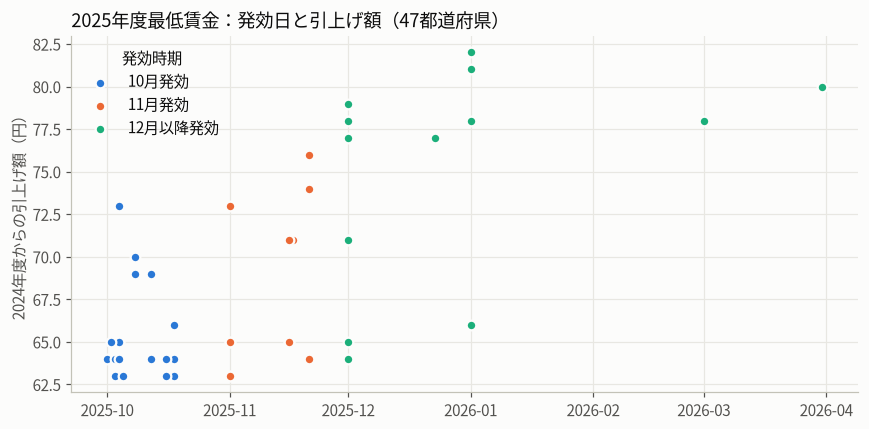

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for g in GROUP_ORDER:
    s = mw[mw["group"] == g]
    ax.scatter(s["effective"], s["raise_yen"], s=40, color=COLORS[g],
               edgecolor="#fcfcfb", linewidth=1.5, label=g, zorder=3)
ax.set_title("2025年度最低賃金：発効日と引上げ額（47都道府県）", loc="left")
ax.set_ylabel("2024年度からの引上げ額（円）")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(title="発効時期", frameon=False)
fig.tight_layout()

**観察：** 発効が遅いグループほど最低賃金の水準が低く、引上げ率が高い（10月発効は平均6.39%、12月以降発効は7.78%）。グループ間では発効時期だけでなく、引上げ幅や地域の特徴も異なる。

## 3. パート新規求人数の記述統計（2023年1月〜2026年8月）

### 3.1 全国の推移と季節性

month,1,2,3,4,5,6,7,8,9,10,11,12
全国・月別平均,"366,544.50","348,478.25","327,606.75","319,823.50","304,796.25","308,296.50","316,394.75","293,749.50","311,779.67","352,424.00","301,811.00","303,590.33"


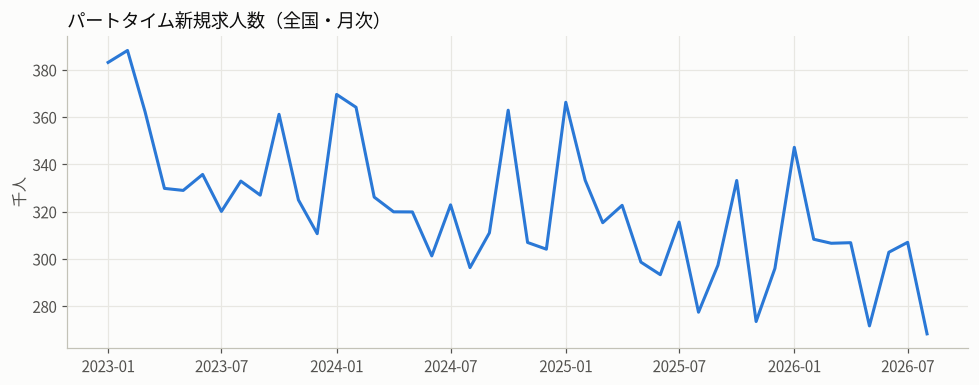

In [9]:
nat = national.loc[START:END]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(nat.index.to_timestamp(), nat / 1000, color="#2a78d6")
ax.set_title("パートタイム新規求人数（全国・月次）", loc="left")
ax.set_ylabel("千人")
fig.tight_layout()

# 月別（1〜12月）の全国平均：1〜8月は4年、9〜12月は3年の平均
nat.groupby(nat.index.month).mean().rename("全国・月別平均").to_frame().T

**観察：** 毎年1月と10月に多く、季節性がはっきりしている。全体としては緩やかな減少傾向にある。各月の水準をそのまま比べると季節性が混ざるため、以下では主に前年同月比を用いる。

### 3.2 都道府県×月パネルの分布

In [10]:
panel = part_wide.reset_index().melt(id_vars="month", var_name="pref", value_name="openings")
panel["log_open"] = np.log(panel["openings"])
panel = panel.sort_values(["pref", "month"])
# 前年同月比（対数差×100、ほぼ%に相当）：季節性を除く
panel["yoy"] = 100 * panel.groupby("pref")["log_open"].diff(12)
panel = panel.join(mw[["group", "mw_2025", "raise_yen", "raise_pct", "effective"]], on="pref")
panel = panel[(panel["month"] >= START) & (panel["month"] <= END)].reset_index(drop=True)
print(f"観測数 {len(panel)} = {panel['pref'].nunique()}都道府県 × {panel['month'].nunique()}か月")

def describe(s):
    return s.describe(percentiles=[.25, .5, .75])

pd.DataFrame({"新規求人数（人）": describe(panel["openings"]),
              "前年同月比（対数差×100）": describe(panel["yoy"])}).T

観測数 2068 = 47都道府県 × 44か月


,count,mean,std,min,25%,50%,75%,max
新規求人数（人）,"2,068.00","6,843.12","8,105.34","1,389.00","2,901.00","4,059.50","7,249.25","62,145.00"
前年同月比（対数差×100）,"2,068.00",-5.17,9.12,-36.20,-10.70,-5.35,0.20,37.82


In [11]:
# 年別：1県1か月あたりの求人数と、前年同月比の平均・中央値
panel.assign(年=panel["month"].dt.year).groupby("年").agg(
    月数=("month", "nunique"),
    求人数_平均=("openings", "mean"),
    求人数_中央値=("openings", "median"),
    前年同月比_平均=("yoy", "mean"),
    前年同月比_中央値=("yoy", "median"),
)

,月数,求人数_平均,求人数_中央値,前年同月比_平均,前年同月比_中央値
年,,,,,
2023,12,"7,278.38","4,394.50",-2.47,-3.11
2024,12,"6,924.08","4,054.00",-7.01,-6.97
2025,12,"6,600.26","3,873.50",-5.81,-5.75
2026,8,"6,433.09","3,848.50",-5.51,-5.58


In [12]:
# 都道府県別の月平均求人数（期間平均）：上位・下位5県
by_pref = panel.groupby("pref")["openings"].mean().sort_values()
pd.concat([by_pref.tail(5).iloc[::-1], by_pref.head(5)], keys=["上位5県", "下位5県"]).rename("月平均求人数").to_frame()

月平均求人数
     pref          
上位5県 東京都  50,530.43
     大阪府  27,431.68
     愛知県  16,974.64
     福岡県  15,455.82
     神奈川県 13,561.07
下位5県 鳥取県   1,807.25
     高知県   1,965.93
     徳島県   2,043.36
     島根県   2,198.34
     山梨県   2,455.25

## 4. 改定前の求人の動き（発効時期グループ別）

### 4.1 改定前のグループの特徴（2025年4〜9月）

各グループの改定前の状況が似ているかを確認する。求人の規模や最低賃金の水準が異なる可能性がある。

In [13]:
pre = panel[(panel["month"] >= pd.Period("2025-04", "M")) & (panel["month"] <= pd.Period("2025-09", "M"))]
pre_pref = pre.groupby("pref").agg(openings=("openings", "mean"), yoy=("yoy", "mean")).join(mw)
pre_pref.groupby("group", observed=True).agg(
    県数=("openings", "size"),
    月平均求人数_平均=("openings", "mean"),
    月平均求人数_中央値=("openings", "median"),
    前年同月比_平均=("yoy", "mean"),
    最低賃金_2025=("mw_2025", "mean"),
    引上げ率=("raise_pct", "mean"),
)

,県数,月平均求人数_平均,月平均求人数_中央値,前年同月比_平均,最低賃金_2025,引上げ率
group,,,,,,
10月発効,20,"9,252.54","5,158.92",-3.94,"1,090.65",6.39
11月発効,13,"5,621.56","3,692.50",-5.00,"1,063.54",6.82
12月以降発効,14,"3,050.56","2,839.00",-5.06,"1,036.71",7.78


**観察：** 10月発効には東京・大阪・愛知などの大都市が含まれ、求人の規模が明らかに大きい（中央値は12月以降発効の約1.8倍）。一方、改定前の前年同月比は3グループとも近い（約−4〜−5）。

### 4.2 前年同月比の推移（2024年1月〜2025年9月）

各月について、グループ内の都道府県の前年同月比を単純平均した。2025年度の最初の発効（2025年10月）より前の期間に限る。

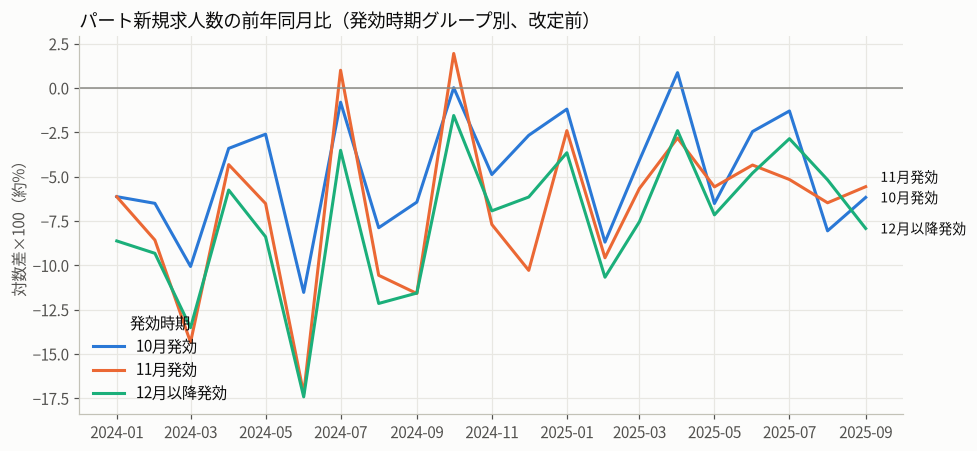

In [14]:
TREND_END = pd.Period("2025-09", "M")

trend = (panel[(panel["month"] >= pd.Period("2024-01", "M")) & (panel["month"] <= TREND_END)]
         .groupby(["month", "group"], observed=True)["yoy"].mean().unstack())
fig, ax = plt.subplots(figsize=(9, 4.2))
x = trend.index.to_timestamp()
for g in GROUP_ORDER:
    ax.plot(x, trend[g], color=COLORS[g], label=g)
# 右端のラベル：重ならないよう下から順に最小間隔をあける
ends = trend.iloc[-1].sort_values()
gap = 0.06 * (trend.max().max() - trend.min().min())
label_y = []
for v in ends:
    label_y.append(max(v, label_y[-1] + gap) if label_y else v)
for g, y in zip(ends.index, label_y):
    ax.text(x[-1] + pd.Timedelta(days=12), y, g, va="center", fontsize=9, color="#0b0b0b")
ax.axhline(0, color="#8a8984", lw=1)

ax.set_title("パート新規求人数の前年同月比（発効時期グループ別、改定前）", loc="left")
ax.set_ylabel("対数差×100（約%）")
ax.legend(title="発効時期", frameon=False, loc="lower left")
fig.tight_layout()

In [15]:
# 同じ内容の数表と、10月発効と12月以降発効の差（2025年1〜9月）
pre_tbl = trend.loc["2025-01":].copy()
pre_tbl["差（10月−12月以降）"] = pre_tbl["10月発効"] - pre_tbl["12月以降発効"]
pre_tbl.round(2)

group,10月発効,11月発効,12月以降発効,差（10月−12月以降）
month,,,,
2025-01,-1.20,-2.41,-3.66,2.46
2025-02,-8.70,-9.58,-10.68,1.98
2025-03,-4.08,-5.67,-7.55,3.46
2025-04,0.86,-2.83,-2.41,3.27
2025-05,-6.52,-5.58,-7.16,0.64
2025-06,-2.46,-4.35,-4.80,2.34
2025-07,-1.30,-5.17,-2.86,1.56
2025-08,-8.06,-6.48,-5.18,-2.88
2025-09,-6.18,-5.57,-7.93,1.75


**観察：** 3グループの前年同月比は、季節による上下を含めておおむね同じように動いている。2025年1〜9月では、10月発効が12月以降発効を上回る月が多い（差は−2.88〜3.46）。発効後の比較では、この改定前の差を考慮する必要がある。

## 5. 次回までに決めること

- 比較期間：発効後のどの月を比べるか（例：発表の案では2025年11月）。
- 仮説：上の記述統計をふまえて、発効時期の違いと求人数の変化の関係を仮説として示す。
- 発効が遅れた理由（各地方最低賃金審議会の資料など）は、データとは別に確認する。

発効後の比較は課題4（仮説の検証）で行う。試しに作った分析は [archive/](../archive/README.md) に置いてある。